# 03 Risk: exposure-adjusted rates (H3) and general kidnapping (H4)

Confirmatory tests of H3 and H4 as fixed in `docs/preregistration.md` (tag `prereg-v1`, amendments in section 8). Data: the incident register (`data/processed/incidents.csv`), modelled exposure (`data/processed/exposure_by_state.csv`) [A09, A10], and for H4 the general kidnapping series (`data/processed/general_kidnapping_by_state.csv`) and the Nigeria Watch series (`data/processed/nigeria_watch_kidnapping_by_state.csv`). Period: 1 January 2010 to the data cutoff of 5 October 2026 [A15]. Alpha = 0.05.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nysc_safety import figures, paths, risk

figures.style()
CUTOFF = date(2026, 10, 5)  # [A15]
TABLES = paths.ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

incidents = pd.read_csv(paths.DATA_PROCESSED / "incidents.csv")
exposure = pd.read_csv(paths.DATA_PROCESSED / "exposure_by_state.csv")
course_figures = pd.read_csv(paths.DATA_INTERIM / "exposure" / "state_course_figures.csv")
national = pd.read_csv(paths.DATA_INTERIM / "exposure" / "national_totals.csv")
incident_sources = figures.id_ranges(s for ids in incidents["source_ids"] for s in ids.split(";"))
exposure_sources = figures.id_ranges(
    [s for ids in course_figures["source_id"].dropna() for s in str(ids).split(";")]
    + [s for ids in national["source_id"].dropna() for s in str(ids).split(";")]
)
print(f"Incident sources: {incident_sources}; exposure sources: {exposure_sources}")

Incident sources: S18-S20, S22-S146, S148-S153; exposure sources: S155-S366


## H3: do incident rates differ across states?

The pre-registered test is a Poisson regression of state incident counts with log exposure as offset, compared by a likelihood-ratio test with an intercept-only model, switching to a negative binomial model if the Pearson dispersion statistic exceeds 1.5. Counts are modelled by state and year (37 states by 17 years), because a model with one count per state and one term per state fits the data exactly and leaves no residual degrees of freedom for the dispersion check (pre-registration amendment of 2026-10-08). Exposure in 2026 is scaled to the share of the year before the cutoff. States with fewer than 1,000 corps members exposed over the period are excluded and listed.

In [2]:
panel = risk.state_year_panel(incidents, exposure, CUTOFF)
panel, small = risk.drop_small_states(panel)
print(f"States excluded for exposure below 1,000: {small or 'none'}")
print(f"{panel['incidents'].sum()} incidents, {panel['exposure'].sum():,.0f} corps-member years of exposure, {panel['state'].nunique()} states")
h3 = risk.h3_test(panel)
pd.Series(h3).to_frame("value")

States excluded for exposure below 1,000: none
96 incidents, 5,096,391 corps-member years of exposure, 37 states


,value
model,poisson
n_obs,629
n_states,37
incidents,96
dispersion_poisson,0.844477
nb_alpha,NaN
lr_statistic,90.205374
df,36
p_value,0.000002


In [3]:
state_table = risk.state_rates(panel)
state_table.to_csv(TABLES / "h3_state_rates.csv", index=False)
state_table.round({"exposed": 0, "rate": 2, "ci_lower": 2, "ci_upper": 2}).head(12)

,state,zone,incidents,exposed,rate,ci_lower,ci_upper,rank_count,rank_rate
0,Akwa Ibom,South South,8,122359.0,0.65,0.28,1.29,3,1
1,Rivers,South South,10,162732.0,0.61,0.29,1.13,1,2
2,Katsina,North West,5,87645.0,0.57,0.19,1.33,5,3
3,FCT,North Central,10,178465.0,0.56,0.27,1.03,1,4
4,Bayelsa,South South,6,124415.0,0.48,0.18,1.05,4,5
5,Zamfara,North West,4,91208.0,0.44,0.12,1.12,6,6
6,Kaduna,North West,4,110040.0,0.36,0.10,0.93,6,7
7,Anambra,South East,4,116237.0,0.34,0.09,0.88,6,8
8,Kogi,North Central,4,120113.0,0.33,0.09,0.85,6,9
9,Benue,North Central,4,139486.0,0.29,0.08,0.73,6,10


In [4]:
from scipy import stats as st
rank_rho = st.spearmanr(state_table["incidents"], state_table["rate"])[0]
moved = state_table[(state_table["rank_count"] - state_table["rank_rate"]).abs() >= 5]
print(f"Spearman correlation of state ranks by count and by rate: {rank_rho:.3f}")
print(f"States whose rank changes by 5 or more places: {len(moved)}")
moved[["state", "incidents", "rate", "rank_count", "rank_rate"]].round(2)

Spearman correlation of state ranks by count and by rate: 0.962
States whose rank changes by 5 or more places: 11


,state,incidents,rate,rank_count,rank_rate
10,Plateau,4,0.27,6,11
13,Ogun,4,0.20,6,14
23,Cross River,1,0.08,19,24
24,Kano,1,0.08,19,25
25,Jigawa,1,0.07,19,26
26,Niger,1,0.06,19,27
27,Delta,1,0.06,19,28
28,Kwara,1,0.06,19,29
29,Osun,1,0.06,19,30
30,Oyo,1,0.05,19,31


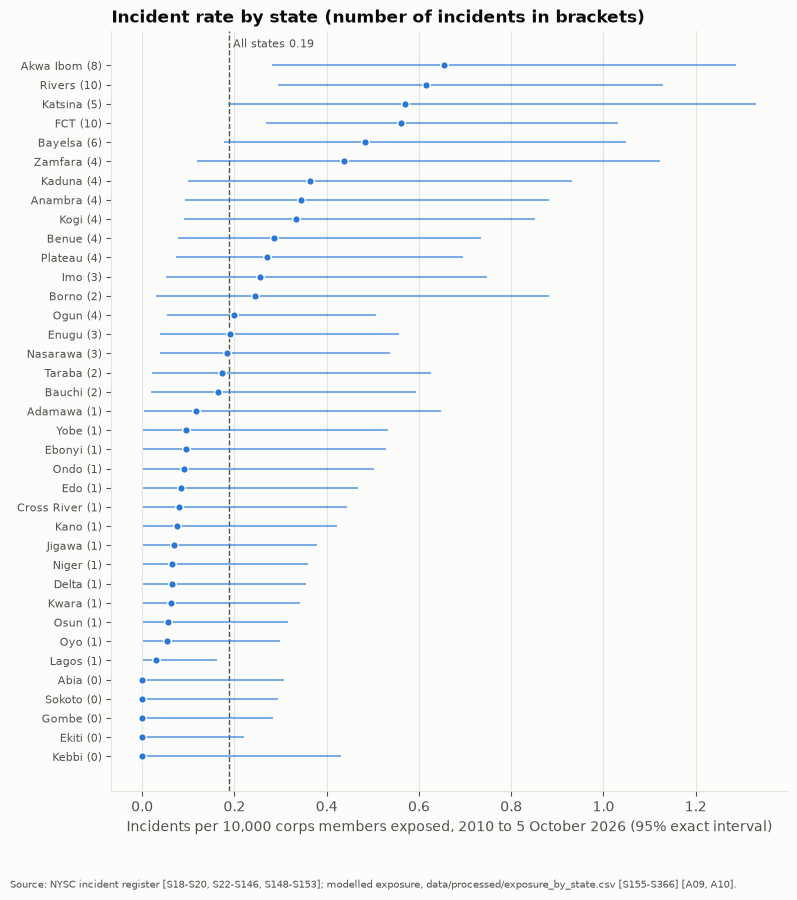

In [5]:
plot = state_table.sort_values("rate")
fig, ax = plt.subplots(figsize=(8, 9))
y = np.arange(len(plot))
ax.hlines(y, plot["ci_lower"], plot["ci_upper"], color=figures.SERIES[0], linewidth=1.5, alpha=0.6, zorder=2)
ax.scatter(plot["rate"], y, s=30, color=figures.SERIES[0], edgecolor="white", linewidth=1, zorder=3)
national_rate = panel["incidents"].sum() / panel["exposure"].sum() * 10_000
ax.axvline(national_rate, color=figures.TEXT_SECONDARY, linewidth=1, linestyle="--", zorder=1)
ax.text(national_rate, len(plot) - 0.2, f" All states {national_rate:.2f}", color=figures.TEXT_SECONDARY, fontsize=8, va="bottom")
ax.set_yticks(y, [f"{s} ({n})" for s, n in zip(plot["state"], plot["incidents"])], fontsize=8)
ax.set_xlabel("Incidents per 10,000 corps members exposed, 2010 to 5 October 2026 (95% exact interval)")
ax.set_title("Incident rate by state (number of incidents in brackets)")
ax.grid(axis="y", visible=False)
figures.save(fig, "h3_incident_rate_by_state",
             f"NYSC incident register [{incident_sources}]; modelled exposure, data/processed/exposure_by_state.csv "
             f"[{exposure_sources}] [A09, A10].")
plt.show()

### H3 robustness

Pre-registered checks: a two-year exposure window [A02]; the test without the five states with the most incidents. Checks set out in A09: exposure shares from sworn-in figures only, and from figures for batches from 2019 onwards only, with the states each variant leaves out listed.

In [6]:
variants = {}
variants["Main"] = (panel, [])
variants["Two-year exposure window"] = (risk.drop_small_states(risk.state_year_panel(incidents, exposure, CUTOFF, window_years=2))[0], [])
top5 = risk.top_states(panel, 5)
variants["Without five states with most incidents"] = (panel[~panel["state"].isin(top5)], top5)
for name, kwargs in {"A09: sworn-in figures only": dict(count_types=("sworn_in",)),
                     "A09: figures for 2019 onwards only": dict(min_batch_year=2019)}.items():
    table = risk.exposure_variant(course_figures, national, **kwargs)
    missing = sorted(set(exposure["state"]) - set(table["state"]))
    variants[name] = (risk.drop_small_states(risk.state_year_panel(incidents, table, CUTOFF))[0], missing)

rows, rankings = {}, {}
for name, (p, left_out) in variants.items():
    rows[name] = {**risk.h3_test(p), "states_left_out": "; ".join(left_out)}
    rankings[name] = risk.state_rates(p).set_index("state")["rate"]
h3_robust = pd.DataFrame(rows).T
h3_robust.to_csv(TABLES / "h3_robustness.csv")
print(f"Five states with most incidents: {top5}")
h3_robust

Five states with most incidents: ['FCT', 'Rivers', 'Akwa Ibom', 'Bayelsa', 'Katsina']


,model,n_obs,n_states,incidents,dispersion_poisson,nb_alpha,lr_statistic,df,p_value,states_left_out
Main,poisson,629,37,96,0.844477,NaN,90.205374,36,0.000002,
Two-year exposure window,poisson,629,37,96,0.82928,NaN,90.205378,36,0.000002,
Without five states with most incidents,poisson,544,32,57,0.816035,NaN,45.696718,31,0.043161,FCT; Rivers; Akwa Ibom; Bayelsa; Katsina
A09: sworn-in figures only,poisson,476,28,79,0.865716,NaN,78.274486,27,0.000001,Borno; Ebonyi; Gombe; Katsina; Niger; Ogun; On...
A09: figures for 2019 onwards only,poisson,629,37,96,0.844467,NaN,95.400827,36,0.0,


In [7]:
rank_check = pd.DataFrame(rankings)
pd.Series({c: rank_check[["Main", c]].dropna().corr(method="spearman").iloc[0, 1] for c in rank_check.columns[1:]},
          name="Spearman with main state rates").round(3).to_frame()

,Spearman with main state rates
Two-year exposure window,1.000
Without five states with most incidents,1.000
A09: sworn-in figures only,0.974
A09: figures for 2019 onwards only,0.987


### H3 result

Over 1 January 2010 to 5 October 2026, the register has 96 incidents against about 5.1 million corps members deployed in modelled exposure, an overall rate of 0.19 incidents per 10,000 [A09, A10]. No state falls below the 1,000-exposed threshold. The Pearson dispersion statistic of the Poisson state model is 0.84, below the 1.5 limit, so the Poisson model is used. The likelihood-ratio test of the 36 state terms against the intercept-only model gives a statistic of 90.2 (df = 36, p = 0.000002). H3 is supported: incident rates per 10,000 corps members differ across states.

The highest rates are in Akwa Ibom (0.65 per 10,000, 8 incidents), Rivers (0.61, 10), Katsina (0.57, 5), the FCT (0.56, 10) and Bayelsa (0.48, 6). Five states have no recorded incident (Abia, Ekiti, Gombe, Kebbi, Sokoto). The intervals are wide, and those of most states overlap.

The ranking by rate is close to the ranking by count (Spearman 0.962). Eleven states move five or more places, almost all of them states with one incident whose tied count rank is broken by exposure. The prediction that rankings by rate differ from rankings by raw count therefore holds only weakly. Under A09 each state's exposure is a fixed share of the national total, so differences in exposure across states are moderate and stable over time, and rates largely follow counts.

Robustness: the result holds with a two-year exposure window (p = 0.000002), with exposure shares from sworn-in figures only (28 states, p = 0.000001) and from figures for 2019 onwards only (p < 0.000001). Without the five states with the most incidents (the FCT, Rivers, Akwa Ibom, Bayelsa and Katsina) the remaining 32 states still differ, more weakly (p = 0.043). Under A09 the two-year window changes exposure in every state by the same factor in each year, so it cannot change the state comparison; it is reported because it was pre-registered. State rates under the two A09 variants correlate at 0.974 and 0.987 with the main rates.